# Vortrainierte Objekterkennung mit YOLO11n

In [1]:
from pathlib import Path

import cv2
from IPython.display import Image, display

ROOT = Path.cwd().resolve()

bus.jpg – person: 4, bus: 1


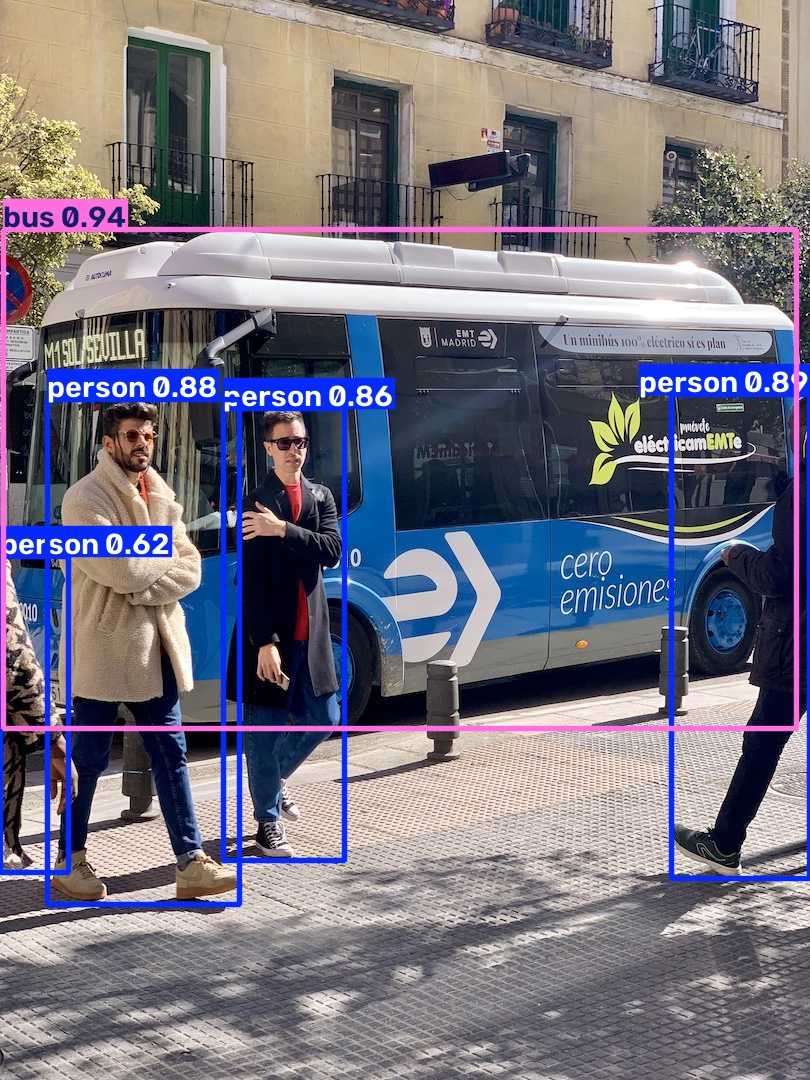

zidane.jpg – person: 2, tie: 1


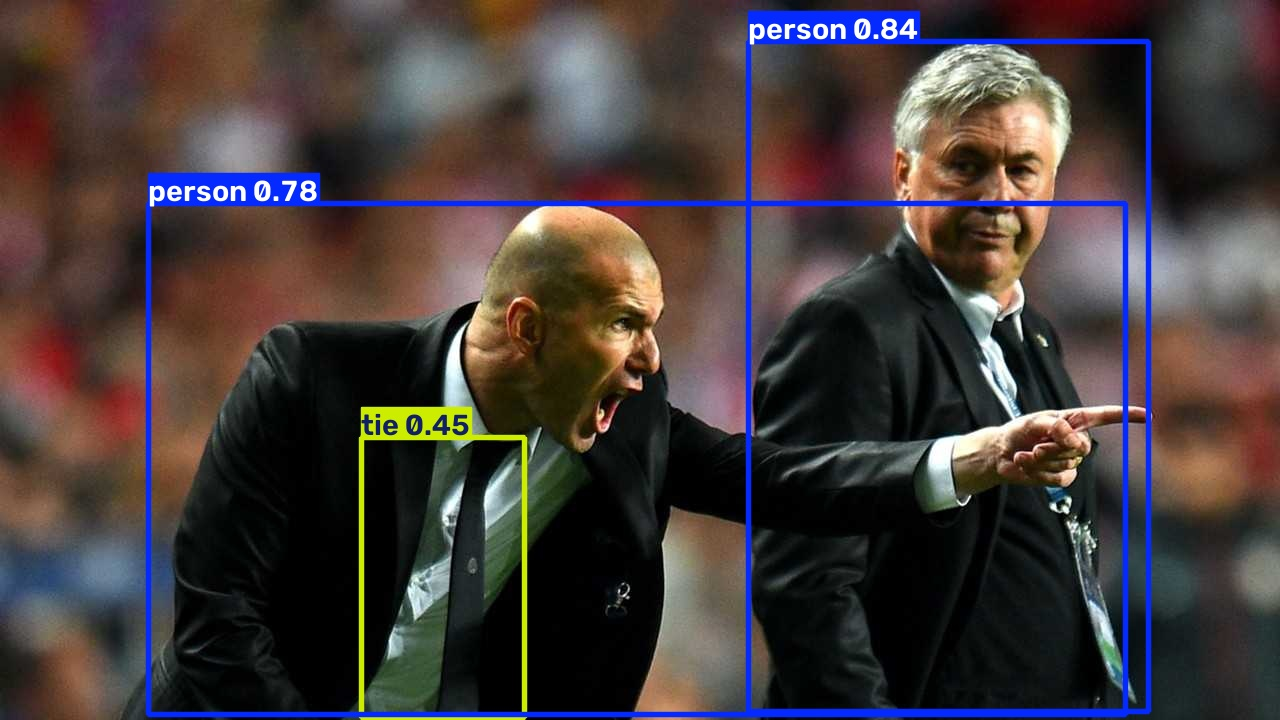

In [2]:
from collections import Counter

from ultralytics import YOLO
from ultralytics.utils import ASSETS

WEIGHTS = ROOT / "models/yolo11n.pt"
IMAGES = [
    ASSETS / "bus.jpg",
    ASSETS / "zidane.jpg",
    # "bilder/mein_foto.jpg",
]
CONFIDENCE = 0.4

image_paths = [ROOT / Path(image).expanduser() for image in IMAGES]
for path in [WEIGHTS, *image_paths]:
    if not path.is_file():
        raise FileNotFoundError(f"Datei fehlt: {path}")

pretrained = YOLO(str(WEIGHTS))
for path in image_paths:
    result = pretrained.predict(str(path), conf=CONFIDENCE, imgsz=640,
                                verbose=False, save=False)[0]
    counts = Counter(result.names[int(index)] for index in result.boxes.cls)
    summary = ", ".join(f"{name}: {count}" for name, count in counts.most_common())
    print(f"{path.name} – {summary or 'Keine Objekte erkannt'}")
    encoded_ok, encoded = cv2.imencode(".jpg", result.plot())
    if not encoded_ok:
        raise ValueError(f"Bild kann nicht angezeigt werden: {path}")
    display(Image(data=encoded.tobytes(), width=720))